# Campaign example

This example reconstructs the measured FE–rate frontier from the final campaign data and demonstrates random initialization, boundary-repulsive farthest-point sampling (BR-FPS), and Bayesian optimization (BO).

In [ ]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
from IPython.display import display

root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "styles" / "manuscript.mplstyle").is_file()
     and (path / "src" / "campaign.py").is_file()),
    None,
)
if root is None:
    raise FileNotFoundError("Start Jupyter in the repository or its notebooks folder.")

sys.path.insert(0, str(root))
from src.campaign import (
    BOSettings, FEATURE_COLUMNS, TARGET_COLUMNS, generate_initial_design,
    propose_bo_batch, select_space_filling,
)
from src.preprocessing import CONDITION
from src.pareto import campaign_objectives, observed_front
from src.preprocessing import load_campaign

style = root / "styles" / "manuscript.mplstyle"
use_tex = False
campaign = load_campaign(root)
display(campaign.history.groupby(["Search-space stage", "Selection strategy"]).size()
        .rename("Conditions").reset_index())
print(f"{len(campaign.eligible)} successful electrolyses")
print(f"{len(campaign.retained)} retained after IQR filtering")

,Search-space stage,Selection strategy,Conditions
0,Stage 1: conditions 1-64,BO,32
1,Stage 1: conditions 1-64,BR-FPS,16
2,Stage 1: conditions 1-64,Random,16
3,Stage 2: conditions 65-112,BO,32
4,Stage 2: conditions 65-112,BR-FPS,16


264 successful electrolyses
259 retained after IQR filtering


## Experimental FE–rate frontier

Average the retained independent electrolyses within each condition. A condition is nondominated if no other measured condition has at least as high an FE and rate and exceeds it in at least one objective. Membership here is based on the condition means.

,Exp #,n independent electrolysis,FE mean (%),Rate mean (nmol/s/cm^2)
97,BO-86,3,31.808232,17.963731
100,BO-89,2,32.738762,12.865676
107,BO-95,2,37.463270,12.537586
93,BO-82,4,43.957460,8.393459


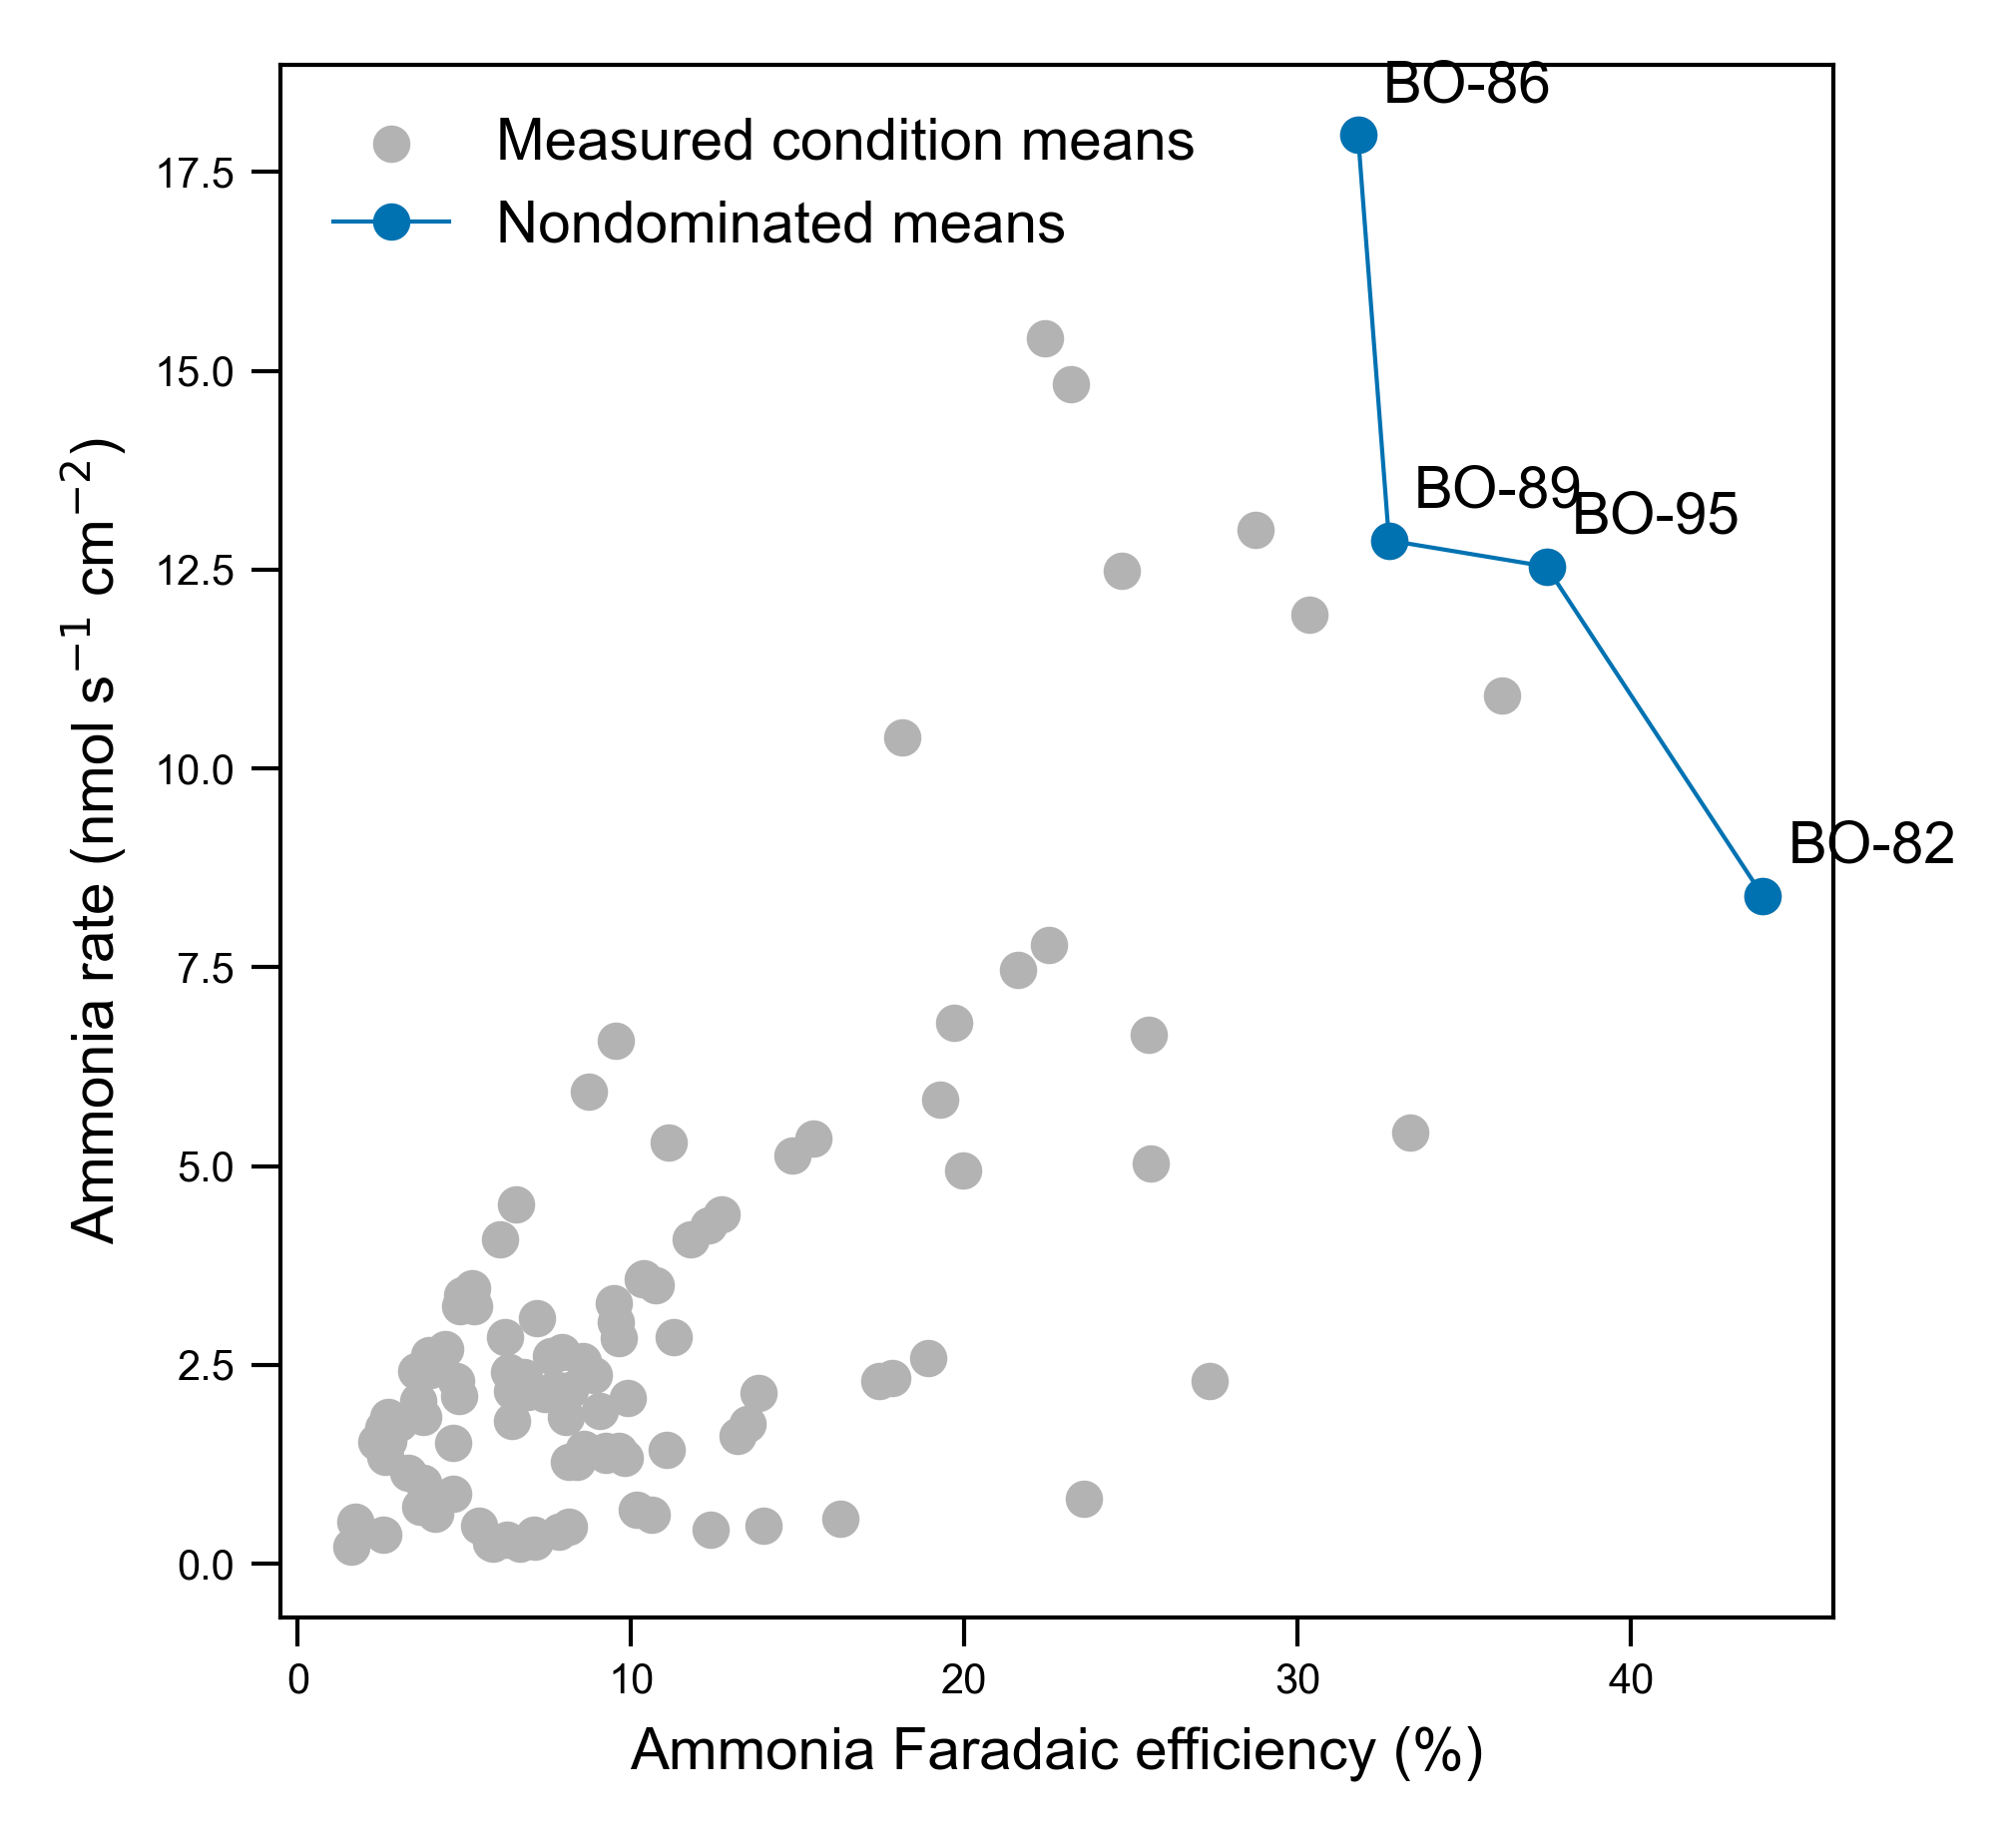

In [ ]:
conditions = observed_front(campaign_objectives(campaign.retained))
fe = "FE mean (%)"
rate = "Rate mean (nmol/s/cm^2)"
front = conditions.loc[conditions["Mean-based Pareto"]].sort_values(fe)
display(front[["Exp #", "n independent electrolysis", fe, rate]])

with plt.style.context(style):
    plt.rcParams["text.usetex"] = use_tex
    fig, ax = plt.subplots(figsize=(3.25, 3.25), layout="constrained")
    ax.scatter(conditions[fe], conditions[rate], color="0.7",
               label="Measured condition means")
    ax.plot(front[fe], front[rate], "o-", label="Nondominated means")
    for label, x, y in front[["Exp #", fe, rate]].itertuples(index=False, name=None):
        ax.annotate(label, (x, y), xytext=(3, 4), textcoords="offset points")
    ax.set(xlabel="Ammonia Faradaic efficiency (%)",
           ylabel=r"Ammonia rate (nmol s$^{-1}$ cm$^{-2}$)")
    ax.set_box_aspect(1)
    ax.legend(frameon=False)
    plt.show()

## Seeded initial-design example

Generate 64 candidate rows using the campaign sampler with explicit NumPy and Torch seeds. These rows demonstrate the sampler. Use the campaign history and replicate table for the actual measured conditions.

In [ ]:
initial_design = generate_initial_design(64, numpy_seed=42, torch_seed=12345)
display(initial_design.head())

,Current density (mA/cm^2),THF (%),LiBF4 concentration (M),LiTFSI concentration (M),BuOH concentration (M),PrOH concentration (M),EtOH concentration (M)
0,3.807947,95.071431,0.737544,0.494450,0.020541,0.000069,0.002793
1,1.644346,5.808361,0.821229,0.544947,0.005857,0.089423,0.010931
2,0.303786,96.990985,0.282930,1.049513,0.020577,0.001766,0.004931
3,1.915705,30.424224,0.442638,0.582118,0.030434,0.006008,0.007242
4,6.157344,13.949386,0.290212,0.501933,0.038104,0.014686,0.015620


## Propose conditions with BR-FPS

Use the first 16 measured conditions as the existing design. BR-FPS selects candidates that improve coverage while penalizing proximity to the bounds. It uses input settings alone. This example proposes four candidates from a reduced candidate pool for a quick demonstration.

In [ ]:
existing = campaign.condition_means.loc[
    campaign.condition_means[CONDITION].between(1, 16), list(FEATURE_COLUMNS)
]
fps_candidates = select_space_filling(
    existing, stage="initial", numpy_seed=123, torch_seed=12345,
    n_new=4, n_candidates=1000,
)
display(fps_candidates)

,Current density (mA/cm^2),THF (%),LiBF4 concentration (M),LiTFSI concentration (M),BuOH concentration (M),PrOH concentration (M),EtOH concentration (M)
0,1.881322,88.998646,0.861977,0.376598,0.125359,0.000419,0.017047
1,9.196501,99.484234,0.506353,0.058342,0.007412,0.113167,0.013834
2,6.097059,72.806879,0.614547,0.424035,0.086485,0.007421,0.020723
3,4.346637,88.270289,1.260859,0.650461,0.073454,0.014500,0.017480


## Propose conditions with Bayesian optimization

Use the retained individual electrolysis rows for the same 16 conditions. The campaign BO method fits separate Gaussian processes for measured FE and rate. It uses constrained qLogNEHVI to propose a batch jointly. The example uses two candidates and reduced optimization settings for a shorter runtime. The returned acquisition value scores the proposed batch, and FE and rate would be measured after electrolysis.

In [ ]:
training = campaign.model_rows.loc[
    campaign.model_rows[CONDITION].between(1, 16),
    [*FEATURE_COLUMNS, *TARGET_COLUMNS],
]
settings = BOSettings(
    stage="initial", seed=12345, batch_size=2, mc_samples=16,
    num_restarts=2, raw_samples=64, n_burnin=100, n_thinning=4,
    batch_limit=2, maxiter=50,
)
bo_candidates, log_acquisition = propose_bo_batch(training, settings)
display(bo_candidates)
print(f"Batch log acquisition value: {log_acquisition:.6f}")

c:\Users\micha\AppData\Local\Programs\Python\Python311\Lib\site-packages\linear_operator\utils\cholesky.py:40: NumericalWarning: A not p.d., added jitter of 1.0e-08 to the diagonal
  warnings.warn(


  NIT    FC           OBJFUN            GNORM
    1     2    -2.512764E-01     3.007184E+01
    2     5    -2.133225E+00     4.874817E+01
    3     7    -1.162098E+00     6.385738E+00
    4     9    -1.189464E+00     2.025850E+01
    5    11    -2.310438E+00     3.076302E+01
    6    14    -1.970430E+00     1.806820E+01
    7    16    -2.566809E+00     1.029369E+01
    8    19    -1.900889E+00     6.616459E+00
    9    22    -2.928930E+00     6.926029E+00
   10    24    -2.997717E+00     1.426143E+01
   11    25    -3.022530E+00     1.334564E+01
   12    26    -3.069446E+00     8.404695E+00
   13    27    -3.192611E+00     7.867990E+00
   14    28    -2.236181E+00     2.107488E+01
   15    30    -2.576455E+00     2.414560E+01
   16    32    -2.589363E+00     2.668378E+01
   17    34    -3.633348E+00     2.571190E+01
   18    35    -3.733926E+00     1.352467E+01
   19    36    -3.219398E+00     6.042588E+00
   20    39    -3.759600E+00     6.300466E+00
   21    40    -3.788459E+00     6

,Current density (mA/cm^2),THF (%),LiBF4 concentration (M),LiTFSI concentration (M),BuOH concentration (M),PrOH concentration (M),EtOH concentration (M)
0,10.000000,73.078936,0.003707,0.496293,0.087525,0.005974,0.011995
1,8.220261,100.000000,0.876791,0.619061,0.017265,0.006291,0.011073


Batch log acquisition value: 2.400980
